# 🔵 **Data Loading & Preprocessing**

# Check GPU / CUDA Availability

In [ ]:
import torch

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU is NOT available")

CUDA available: True
GPU: NVIDIA A100-SXM4-40GB


# Install and Import Required Libraries

In [ ]:
!pip install -q segmentation-models-pytorch

In [ ]:
import os
import zipfile

from PIL import Image

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import seaborn as sns
%matplotlib inline

import albumentations as albu
from albumentations.pytorch import ToTensorV2

from sklearn.model_selection import train_test_split

import torch
from torch.utils.data import Dataset
from torch.utils.data import DataLoader
import torch.nn as nn

import cv2

import torch.optim as optim
from torch.optim.lr_scheduler import ReduceLROnPlateau

import segmentation_models_pytorch as smp

# Load DATA

In [ ]:
from google.colab import drive
drive.mount('/content/drive')


# =========================
# Paths
# =========================

DATA_DIR = "/content/drive/MyDrive"

CLOUD_DATA_ZIP = os.path.join(DATA_DIR, "cloud-data.zip")
TEST_ZIP = os.path.join(DATA_DIR, "test_images.zip")


# =========================
# Extract training data
# =========================

TRAIN_DATA_DIR = "/content/cloud_data"

with zipfile.ZipFile(CLOUD_DATA_ZIP, "r") as zip_ref:
    zip_ref.extractall(TRAIN_DATA_DIR)


# =========================
# Extract test data
# =========================

TEST_DATA_DIR = "/content/test_images"

with zipfile.ZipFile(TEST_ZIP, "r") as zip_ref:
    zip_ref.extractall(TEST_DATA_DIR)


# =========================
# Actual data paths
# =========================

TRAIN_IMAGES_DIR = "/content/cloud_data/data/train_images"
TRAIN_CSV = "/content/cloud_data/data/train.csv"
TEST_IMAGES_DIR = "/content/test_images/test_images"

print("Train images exists:", os.path.exists(TRAIN_IMAGES_DIR))
print("Train CSV exists:", os.path.exists(TRAIN_CSV))
print("Test images exists:", os.path.exists(TEST_IMAGES_DIR))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Train images exists: True
Train CSV exists: True
Test images exists: True


# Load and Inspect the Dataset

In [ ]:
# =========================
# Load training CSV
# =========================

train = pd.read_csv(TRAIN_CSV)

print("Train CSV shape:", train.shape)
print("\nColumns:")
print(train.columns.tolist())

print("\nFirst 5 rows:")
display(train.head())


# =========================
# Split Image_Label
# =========================

train[["Image_id", "Cloud_Type"]] = train["Image_Label"].str.split(
    "_", expand=True
)

train = train[["Image_id", "Cloud_Type", "EncodedPixels"]]

print("\nAfter splitting:")
display(train.head())


# =========================
# Check basic dataset information
# =========================

print("\nNumber of annotation rows:", len(train))
print("Number of unique images:", train["Image_id"].nunique())

print("\nCloud type counts:")
print(train["Cloud_Type"].value_counts())


# =========================
# Check image resolution
# =========================

image_files = [
    f for f in os.listdir(TRAIN_IMAGES_DIR)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]

print("\nNumber of training image files:", len(image_files))

# Read first image
first_image_path = os.path.join(TRAIN_IMAGES_DIR, image_files[0])

first_image = Image.open(first_image_path)

print("First image:", image_files[0])
print("Image size (width, height):", first_image.size)
print("Image mode:", first_image.mode)


# =========================
# Verify resolution across dataset
# =========================

sizes = {}

for filename in image_files:
    with Image.open(os.path.join(TRAIN_IMAGES_DIR, filename)) as img:
        sizes[img.size] = sizes.get(img.size, 0) + 1

print("\nImage resolutions:")
for size, count in sizes.items():
    print(size, "->", count, "images")

Train CSV shape: (22184, 2)

Columns:
['Image_Label', 'EncodedPixels']

First 5 rows:


,Image_Label,EncodedPixels
0,0011165.jpg_Fish,20056 257 20440 257 20824 257 21208 257 21592 ...
1,0011165.jpg_Flower,102135 1 102245 275 102629 275 103013 275 1033...
2,0011165.jpg_Gravel,NaN
3,0011165.jpg_Sugar,NaN
4,002be4f.jpg_Fish,17668 241 18051 242 18435 242 18819 242 19203 ...



After splitting:


,Image_id,Cloud_Type,EncodedPixels
0,0011165.jpg,Fish,20056 257 20440 257 20824 257 21208 257 21592 ...
1,0011165.jpg,Flower,102135 1 102245 275 102629 275 103013 275 1033...
2,0011165.jpg,Gravel,NaN
3,0011165.jpg,Sugar,NaN
4,002be4f.jpg,Fish,17668 241 18051 242 18435 242 18819 242 19203 ...



Number of annotation rows: 22184
Number of unique images: 5546

Cloud type counts:
Cloud_Type
Fish      5546
Flower    5546
Gravel    5546
Sugar     5546
Name: count, dtype: int64

Number of training image files: 5546
First image: d2c4532.jpg
Image size (width, height): (576, 384)
Image mode: RGB

Image resolutions:
(576, 384) -> 5546 images


# Decode RLE and Create Multi-Channel Ground Truth Masks

In [ ]:
# =========================
# Decode RLE
# =========================

def rle_decode(rle, shape=(384, 576)):
    mask = np.zeros(shape[0] * shape[1], dtype=np.uint8)

    if pd.isna(rle):
        return mask.reshape(shape)

    numbers = list(map(int, rle.split()))

    starts = numbers[0::2]
    lengths = numbers[1::2]

    for start, length in zip(starts, lengths):
        start -= 1
        mask[start:start + length] = 1

    return mask.reshape(shape, order="F")
  # ===========================
  #create_multichannel_mask
  # ========================

def create_multichannel_mask(image_id, df):
    """
    Create a 4-channel mask for one image.
    Returns: numpy array of shape (H, W, 4) with dtype float32
    """

    # Get image dimensions from the global constants
    height = 384
    width = 576

    mask = np.zeros(
        (height, width, 4),
        dtype=np.float32
    )

    image_rows = df[
        df["Image_id"] == image_id
    ]

    class_map = {
        "Fish": 0,
        "Flower": 1,
        "Gravel": 2,
        "Sugar": 3
    }

    for _, row in image_rows.iterrows():

        if pd.notna(row["EncodedPixels"]):

            channel = class_map[
                row["Cloud_Type"]
            ]

            binary_mask = rle_decode(
                row["EncodedPixels"],
                shape=(height, width)
            )

            mask[:, :, channel] = binary_mask

    return mask

# Define Training Data Augmentation and Preprocessing

In [ ]:
def get_train_transforms():
    return albu.Compose([
        albu.HorizontalFlip(p=0.5),
        albu.VerticalFlip(p=0.5),

        albu.ShiftScaleRotate(
            shift_limit=0.1,
            scale_limit=0.15,
            rotate_limit=20,
            border_mode=0,
            p=0.5
        ),

        albu.OneOf([
            albu.RandomBrightnessContrast(p=1),
            albu.RandomGamma(p=1),
            albu.CLAHE(p=1),
        ], p=0.5),

        albu.OneOf([
            albu.GaussNoise(p=1),
            albu.GaussianBlur(p=1),
            albu.MotionBlur(p=1),
        ], p=0.3),

        albu.Resize(
            height=384,
            width=576
        ),

        albu.Normalize(
            mean=(0.485, 0.456, 0.406),
            std=(0.229, 0.224, 0.225)
        ),

        ToTensorV2()
    ])


def get_valid_transforms():
    return albu.Compose([
        albu.Resize(
            height=384,
            width=576
        ),

        albu.Normalize(
            mean=(0.485, 0.456, 0.406),
            std=(0.229, 0.224, 0.225)
        ),

        ToTensorV2()
    ])

# CloudDataset(Dataset) - Custom Dataset Class

In [ ]:
class CloudDataset(Dataset):
    def __init__(self, df, image_ids, images_dir, transforms=None, is_test=False):
        self.df = df
        self.image_ids = list(image_ids)
        self.images_dir = images_dir
        self.transforms = transforms
        self.is_test = is_test

    def __len__(self):
        return len(self.image_ids)

    def __getitem__(self, idx):
        image_id = self.image_ids[idx]
        image_path = os.path.join(self.images_dir, image_id)

        # Load image
        image = np.array(Image.open(image_path).convert("RGB"))

        if self.is_test:
            if self.transforms:
                augmented = self.transforms(image=image)
                image = augmented["image"]
            return image, image_id

        # Ground truth mask (H, W, 4)
        mask = create_multichannel_mask(image_id, self.df)

        # Apply transforms
        if self.transforms:
            augmented = self.transforms(image=image, mask=mask)
            image = augmented["image"]
            mask = augmented["mask"]

        # Convert mask to (4, H, W)
        if isinstance(mask, np.ndarray):
            mask = torch.from_numpy(mask).permute(2, 0, 1).float()
        else:
            mask = mask.permute(2, 0, 1).float()

        return image, mask, image_id

# Create Training and Validation Datasets and DataLoaders

In [ ]:
image_ids = train["Image_id"].unique()

train_ids, valid_ids = train_test_split(
    image_ids,
    test_size=0.1,
    random_state=42
)

train_dataset = CloudDataset(
    df=train,
    image_ids=train_ids,
    images_dir=TRAIN_IMAGES_DIR,
    transforms=get_train_transforms(),
    is_test=False
)

valid_dataset = CloudDataset(
    df=train,
    image_ids=valid_ids,
    images_dir=TRAIN_IMAGES_DIR,
    transforms=get_valid_transforms(),
    is_test=False
)

train_loader = DataLoader(
    train_dataset,
    batch_size=8,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

valid_loader = DataLoader(
    valid_dataset,
    batch_size=8,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

print("Train images:", len(train_dataset))
print("Validation images:", len(valid_dataset))
print("Train batches:", len(train_loader))
print("Validation batches:", len(valid_loader))

Train images: 4991
Validation images: 555
Train batches: 624
Validation batches: 70


/usr/local/lib/python3.13/dist-packages/albumentations/core/validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)


# 🔵 **Model Training**

# Define Dice + BCE Loss and Dice Score Metric

In [ ]:
# =========================
# Dice + BCE Loss
# =========================

class DiceBCELoss(nn.Module):

    def __init__(
        self,
        weight_dice=0.7,
        weight_bce=0.3,
        smooth=1e-5
    ):
        super().__init__()

        self.weight_dice = weight_dice
        self.weight_bce = weight_bce
        self.smooth = smooth

        self.bce = nn.BCEWithLogitsLoss()

    def forward(self, logits, targets):

        # BCE Loss
        bce_loss = self.bce(logits, targets)

        # Dice Loss
        probs = torch.sigmoid(logits)

        dims = (2, 3)

        intersection = (
            probs * targets
        ).sum(dims)

        cardinality = (
            probs.sum(dims)
            + targets.sum(dims)
        )

        dice = (
            2.0 * intersection + self.smooth
        ) / (
            cardinality + self.smooth
        )

        dice_loss = 1.0 - dice.mean()

        # Combined Loss
        total_loss = (
            self.weight_bce * bce_loss
            + self.weight_dice * dice_loss
        )

        return total_loss


criterion = DiceBCELoss(
    weight_dice=0.7,
    weight_bce=0.3
)

In [ ]:
def dice_score(logits, targets, threshold=0.5, smooth=1e-5):
    probs = torch.sigmoid(logits)
    preds = (probs > threshold).float()

    dims = (2, 3)
    intersection = (preds * targets).sum(dims)
    cardinality = preds.sum(dims) + targets.sum(dims)
    dice = (2. * intersection + smooth) / (cardinality + smooth)
    return dice.mean().item()

# Define Training and Validation Functions

In [ ]:
def train_one_epoch(model, loader, optimizer, criterion, device):
    model.train()
    running_loss = 0.0

    for images, masks, _ in loader:
        images = images.to(device)
        masks = masks.to(device)

        optimizer.zero_grad()
        logits = model(images)
        loss = criterion(logits, masks)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    return running_loss / len(loader)


@torch.no_grad()
def validate(model, loader, criterion, device):
    model.eval()
    running_loss = 0.0
    running_dice = 0.0

    for images, masks, _ in loader:
        images = images.to(device)
        masks = masks.to(device)

        logits = model(images)
        loss = criterion(logits, masks)
        dice = dice_score(logits, masks)

        running_loss += loss.item()
        running_dice += dice

    return running_loss / len(loader), running_dice / len(loader)

In [ ]:
def train_model(
    model,
    train_loader,
    valid_loader,
    optimizer,
    scheduler,
    criterion,
    device,
    epochs=30,
    early_stopping_patience=5
):
    best_dice = 0.0
    patience_counter = 0

    history = {
        "train_loss": [],
        "val_loss": [],
        "val_dice": []
    }

    checkpoint_dir = "/content/drive/MyDrive/data/checkpoints_resnet50"
    os.makedirs(checkpoint_dir, exist_ok=True)

    best_model_path = os.path.join(
        checkpoint_dir,
        "best_model_resnet50.pth"
    )

    for epoch in range(1, epochs + 1):

        print(f"\nEpoch {epoch}/{epochs}")
        print("-" * 40)

        # Training
        train_loss = train_one_epoch(
            model,
            train_loader,
            optimizer,
            criterion,
            device
        )

        # Validation
        val_loss, val_dice = validate(
            model,
            valid_loader,
            criterion,
            device
        )

        # Scheduler
        scheduler.step(val_loss)

        # Save history
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["val_dice"].append(val_dice)

        # Results
        print(f"Train Loss : {train_loss:.4f}")
        print(f"Val Loss   : {val_loss:.4f}")
        print(f"Val Dice   : {val_dice:.4f}")

        # Best model
        if val_dice > best_dice:

            best_dice = val_dice
            patience_counter = 0

            torch.save(
                model.state_dict(),
                best_model_path
            )

            print(
                f"→ Best model saved "
                f"(Dice: {best_dice:.4f})"
            )

        else:

            patience_counter += 1

            print(
                f"→ No improvement "
                f"({patience_counter}/{early_stopping_patience})"
            )

            if patience_counter >= early_stopping_patience:

                print("Early stopping triggered.")
                break

    print(
        f"\nTraining finished. "
        f"Best Dice: {best_dice:.4f}"
    )

    print(
        f"Best model path: {best_model_path}"
    )

    return history

# Set Computing Device

In [ ]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)

Using device: cuda


# ResNet50 Model Setup and Training

In [ ]:
# =========================
# ResNet50 Model
# =========================

model = smp.Unet(
    encoder_name="resnet50",
    encoder_weights="imagenet",
    in_channels=3,
    classes=4,
    activation=None
)
model = model.to(device)


# =========================
# Optimizer & Scheduler
# =========================

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=8e-5,
    weight_decay=1e-4
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=3
)


#=========================
#ResNet50 Checkpoint Folder
#=========================

CHECKPOINT_DIR = "/content/drive/MyDrive/data/checkpoints_resnet50"

os.makedirs(CHECKPOINT_DIR, exist_ok=True)

In [ ]:
!pip install torchinfo

In [ ]:
from torchinfo import summary

summary(
    model,
    input_size=(1, 3, 384, 576)
)

Layer (type:depth-idx)                        Output Shape              Param #
Unet                                          [1, 4, 384, 576]          --
├─ResNetEncoder: 1-1                          [1, 3, 384, 576]          --
│    └─Conv2d: 2-1                            [1, 64, 192, 288]         9,408
│    └─BatchNorm2d: 2-2                       [1, 64, 192, 288]         128
│    └─ReLU: 2-3                              [1, 64, 192, 288]         --
│    └─MaxPool2d: 2-4                         [1, 64, 96, 144]          --
│    └─Sequential: 2-5                        [1, 256, 96, 144]         --
│    │    └─Bottleneck: 3-1                   [1, 256, 96, 144]         75,008
│    │    └─Bottleneck: 3-2                   [1, 256, 96, 144]         70,400
│    │    └─Bottleneck: 3-3                   [1, 256, 96, 144]         70,400
│    └─Sequential: 2-6                        [1, 512, 48, 72]          --
│    │    └─Bottleneck: 3-4                   [1, 512, 48, 72]          379,392

In [ ]:
# # =========================
# # Start Training
# # =========================
# history = train_model(
#     model=model,
#     train_loader=train_loader,
#     valid_loader=valid_loader,
#     optimizer=optimizer,
#     scheduler=scheduler,
#     criterion=criterion,
#     device=device,
#     epochs=25,
#     early_stopping_patience=5
# )


Epoch 1/25
----------------------------------------
Train Loss : 0.6734
Val Loss   : 0.6239
Val Dice   : 0.4066
→ Best model saved (Dice: 0.4066)

Epoch 2/25
----------------------------------------
Train Loss : 0.6191
Val Loss   : 0.6040
Val Dice   : 0.4304
→ Best model saved (Dice: 0.4304)

Epoch 3/25
----------------------------------------
Train Loss : 0.6105
Val Loss   : 0.5961
Val Dice   : 0.4286
→ No improvement (1/5)

Epoch 4/25
----------------------------------------
Train Loss : 0.6056
Val Loss   : 0.5971
Val Dice   : 0.4482
→ Best model saved (Dice: 0.4482)

Epoch 5/25
----------------------------------------
Train Loss : 0.6015
Val Loss   : 0.5914
Val Dice   : 0.4641
→ Best model saved (Dice: 0.4641)

Epoch 6/25
----------------------------------------
Train Loss : 0.6000
Val Loss   : 0.5898
Val Dice   : 0.4764
→ Best model saved (Dice: 0.4764)

Epoch 7/25
----------------------------------------
Train Loss : 0.5974
Val Loss   : 0.5887
Val Dice   : 0.4904
→ Best model sav

# Best Model Selection and Loading

In [ ]:
print(os.path.exists(
    "/content/drive/MyDrive/data/checkpoints_resnet50/best_model_resnet50.pth"
))

True


In [ ]:
# =========================
# Load Best ResNet50 Model
# =========================

model = smp.Unet(
    encoder_name="resnet50",
    encoder_weights="imagenet",
    in_channels=3,
    classes=4,
    activation=None
)

model = model.to(device)

model.load_state_dict(
    torch.load(
        "/content/drive/MyDrive/data/checkpoints_resnet50/best_model_resnet50.pth",
        map_location=device
    )
)

model.eval()

print("Best ResNet50 model loaded successfully.")

Best ResNet50 model loaded successfully.


# 🔵 **Model Evaluation**

# Training and Validation Loss Curves

In [ ]:
# import os

# base_path = "/content/drive/MyDrive"

# for root, dirs, files in os.walk(base_path):
#     for file in files:
#         if any(word in file.lower() for word in ["history", "loss", "training", "resnet50"]):
#             print(os.path.join(root, file))

In [ ]:
# import json

# notebook_path = "/content/drive/MyDrive/Colab Notebooks/ResNet50CloudSegmentationProject.ipynb"

# with open(notebook_path, "r", encoding="utf-8") as f:
#     notebook = json.load(f)

# for i, cell in enumerate(notebook["cells"]):
#     source = "".join(cell.get("source", []))

#     if "history" in source or "train_loss" in source or "val_loss" in source:
#         print(f"\n===== CELL {i} =====")
#         print(source[:3000])

In [ ]:
# import json

# notebook_path = "/content/drive/MyDrive/Colab Notebooks/ResNet50CloudSegmentationProject.ipynb"

# with open(notebook_path, "r", encoding="utf-8") as f:
#     notebook = json.load(f)

# cell = notebook["cells"][31]

# print("Cell type:", cell["cell_type"])
# print("\n--- OUTPUT ---")

# for output in cell.get("outputs", []):
#     if "text" in output:
#         print("".join(output["text"]))

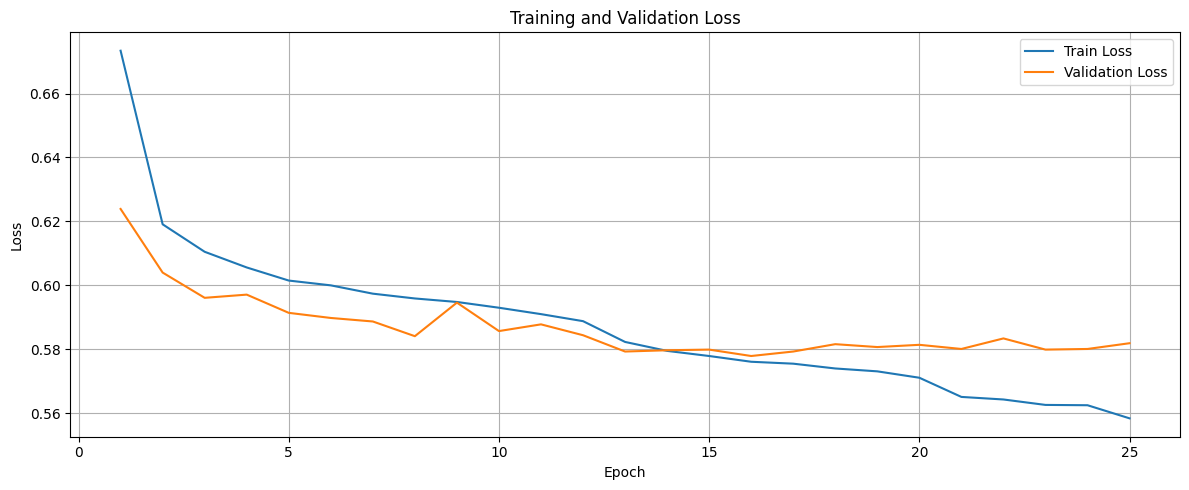

In [ ]:
epochs = range(1, len(history["train_loss"]) + 1)

plt.figure(figsize=(12, 5))

plt.plot(
    epochs,
    history["train_loss"],
    label="Train Loss"
)

plt.plot(
    epochs,
    history["val_loss"],
    label="Validation Loss"
)

plt.title("Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid()

plt.tight_layout()
plt.show()

# Final Validation Performance

In [ ]:
model.eval()

val_loss, val_dice = validate(
    model,
    valid_loader,
    criterion,
    device
)

print("\nValidation performance")
print(f"Validation Loss: {val_loss:.4f}")
print(f"Validation Dice: {val_dice:.4f}")


Validation performance
Validation Loss: 0.5819
Validation Dice: 0.5317


# Validation Dice Score Evaluation

In [ ]:
@torch.no_grad()
def evaluate_model(model, loader, device, threshold=0.5):
    model.eval()

    total_dice = 0.0
    num_batches = 0

    for images, masks, _ in loader:
        images = images.to(device)
        masks = masks.to(device)

        logits = model(images)
        dice = dice_score(logits, masks, threshold=threshold)

        total_dice += dice
        num_batches += 1

    return total_dice / num_batches


val_dice = evaluate_model(
    model,
    valid_loader,
    device,
    threshold=0.5
)

print(f"Validation Dice Score: {val_dice:.4f}")

Validation Dice Score: 0.5317


# Per-Class Dice Score Evaluation

In [ ]:
@torch.no_grad()
def per_class_dice(model, loader, device, threshold=0.5):
    model.eval()

    intersection = torch.zeros(4, device=device)
    cardinality = torch.zeros(4, device=device)

    for images, masks, _ in loader:
        images = images.to(device)
        masks = masks.to(device)

        logits = model(images)
        probs = torch.sigmoid(logits)
        preds = (probs > threshold).float()

        intersection += (preds * masks).sum(dim=(0, 2, 3))
        cardinality += (
            preds.sum(dim=(0, 2, 3))
            + masks.sum(dim=(0, 2, 3))
        )

    dice = (
        2 * intersection + 1e-5
    ) / (
        cardinality + 1e-5
    )

    return dice.cpu().numpy()


class_names = [
    "Fish",
    "Flower",
    "Gravel",
    "Sugar"
]

class_dice = per_class_dice(
    model,
    valid_loader,
    device,
    threshold=0.5
)

for name, score in zip(class_names, class_dice):
    print(f"{name}: {score:.4f}")

overall_dice = np.mean(class_dice)

print(f"Overall Dice Score: {overall_dice:.4f}")

Fish: 0.5478
Flower: 0.6962
Gravel: 0.5729
Sugar: 0.6301
Overall Dice Score: 0.6118


# IoU Evaluation

In [ ]:
# =========================
# IoU Evaluation
# =========================

@torch.no_grad()
def per_class_iou(model, loader, device, threshold=0.5):
    model.eval()

    intersection = torch.zeros(4, device=device)
    union = torch.zeros(4, device=device)

    for images, masks, _ in loader:
        images = images.to(device)
        masks = masks.to(device)

        logits = model(images)

        probs = torch.sigmoid(logits)
        preds = (probs > threshold).float()

        intersection += (
            preds * masks
        ).sum(dim=(0, 2, 3))

        union += (
            preds + masks - preds * masks
        ).sum(dim=(0, 2, 3))

    iou = (
        intersection + 1e-5
    ) / (
        union + 1e-5
    )

    return iou.cpu().numpy()


class_iou = per_class_iou(
    model,
    valid_loader,
    device,
    threshold=0.5
)

for name, score in zip(class_names, class_iou):
    print(f"{name}: {score:.4f}")

print(f"Mean IoU: {class_iou.mean():.4f}")

Fish: 0.3772
Flower: 0.5340
Gravel: 0.4014
Sugar: 0.4600
Mean IoU: 0.4432


# Validation Performance — Dice & IoU

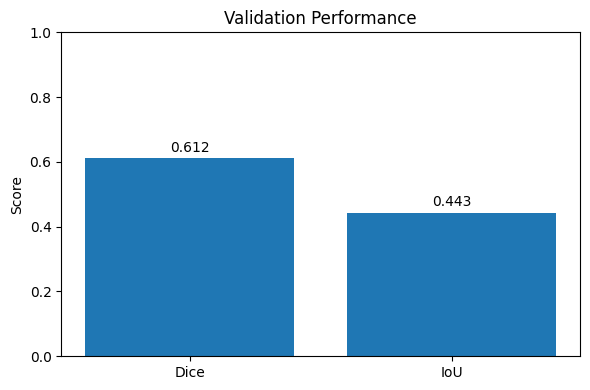

In [ ]:
metrics_to_plot = {
    "Dice": overall_dice,
    "IoU": class_iou.mean()
}

plt.figure(figsize=(6, 4))

plt.bar(
    metrics_to_plot.keys(),
    metrics_to_plot.values()
)

plt.ylim(0, 1)
plt.ylabel("Score")
plt.title("Validation Performance")

for i, value in enumerate(metrics_to_plot.values()):
    plt.text(
        i,
        value + 0.02,
        f"{value:.3f}",
        ha="center"
    )

plt.tight_layout()
plt.show()

# Prepare Validation Predictions for Visualization

In [ ]:
class_names = ["Fish", "Flower", "Gravel", "Sugar"]

model.eval()

with torch.no_grad():
    images, masks, image_ids = next(iter(valid_loader))

    images = images.to(device)

    logits = model(images)
    probs = torch.sigmoid(logits)
    preds = (probs > 0.5).float()

print("Images:", images.shape)
print("Ground Truth:", masks.shape)
print("Prediction:", preds.shape)

Images: torch.Size([8, 3, 384, 576])
Ground Truth: torch.Size([8, 4, 384, 576])
Prediction: torch.Size([8, 4, 384, 576])


# Prediction Visualization

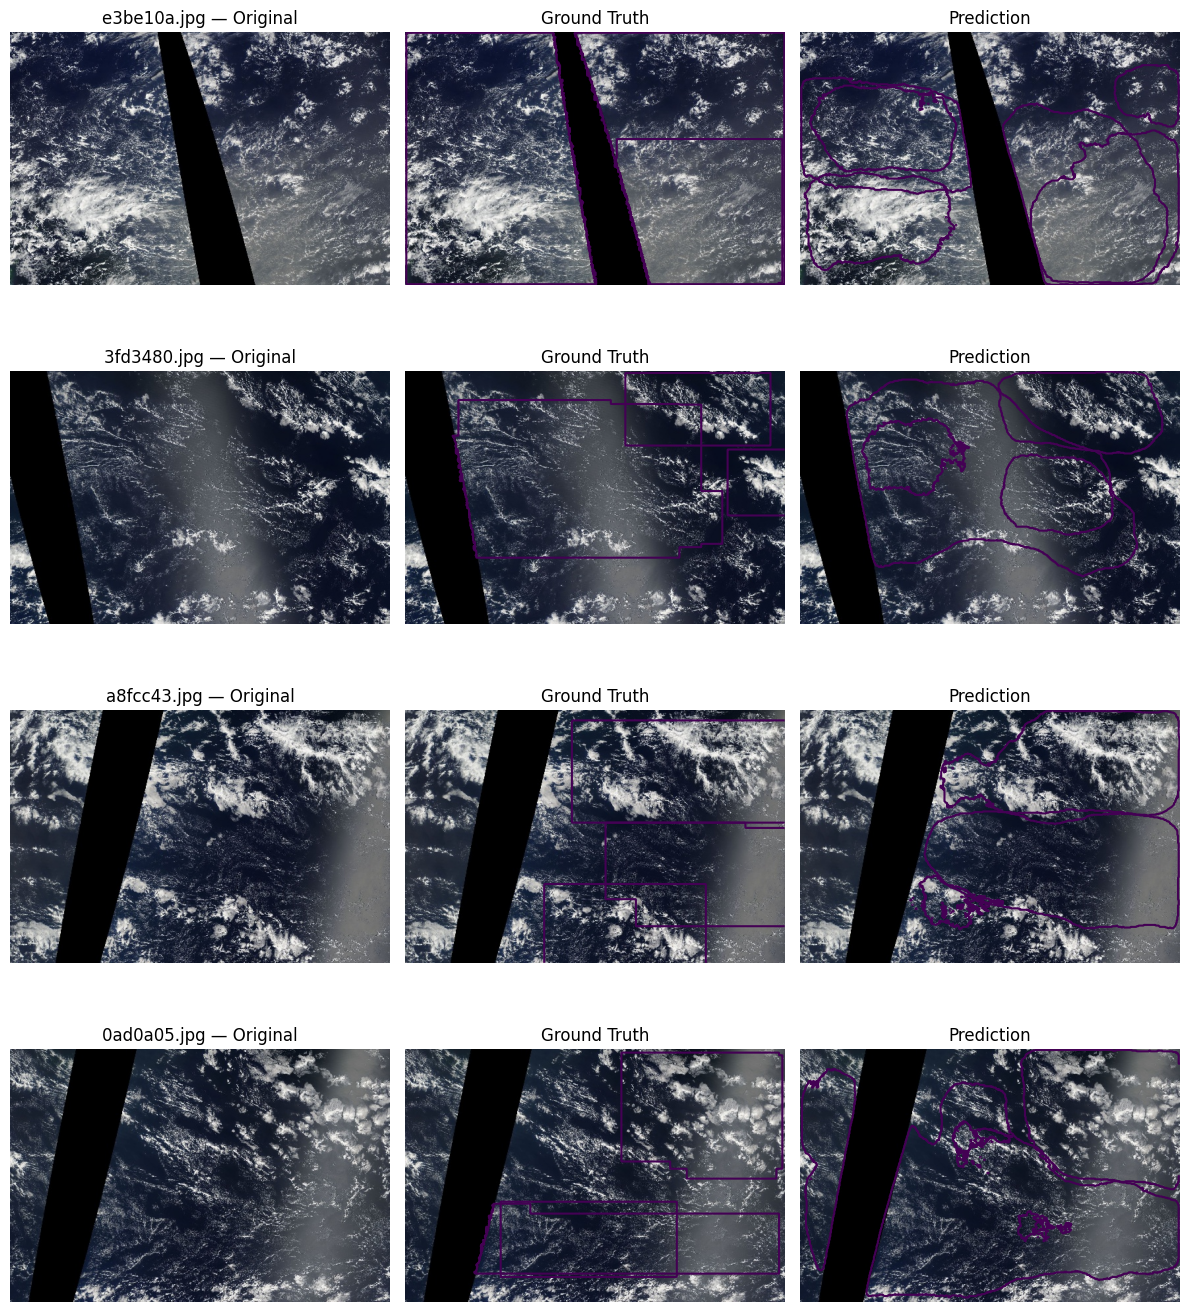

In [ ]:
class_names = ["Fish", "Flower", "Gravel", "Sugar"]

fig, axes = plt.subplots(
    4, 3,
    figsize=(12, 14)
)

for i in range(4):

    # Original image
    image = images[i].cpu().numpy()
    image = image.transpose(1, 2, 0)

    # Undo ImageNet normalization
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])

    image = image * std + mean
    image = np.clip(image, 0, 1)

    # Ground truth
    ground_truth = masks[i].cpu().numpy()

    # Prediction
    prediction = preds[i].cpu().numpy()

    # Original image
    axes[i, 0].imshow(image)
    axes[i, 0].set_title(f"{image_ids[i]} — Original")
    axes[i, 0].axis("off")

    # Ground Truth
    axes[i, 1].imshow(image)

    for c in range(4):
        if ground_truth[c].sum() > 0:
            axes[i, 1].contour(
                ground_truth[c],
                levels=[0.5],
                linewidths=1.5
            )

    axes[i, 1].set_title("Ground Truth")
    axes[i, 1].axis("off")

    # Prediction
    axes[i, 2].imshow(image)

    for c in range(4):
        if prediction[c].sum() > 0:
            axes[i, 2].contour(
                prediction[c],
                levels=[0.5],
                linewidths=1.5
            )

    axes[i, 2].set_title("Prediction")
    axes[i, 2].axis("off")


plt.tight_layout()
plt.show()

# 🔵 **Test Prediction & Final Submission**

# Test Set Prediction

In [ ]:
TEST_DIR = TEST_IMAGES_DIR

CLASSES = [
    "Fish",
    "Flower",
    "Gravel",
    "Sugar"
]

THRESHOLDS = np.array([
    0.5,
    0.5,
    0.5,
    0.5
])

# Get test image names
test_images = [
    f for f in os.listdir(TEST_DIR)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]

# Randomly choose 4 images
random_images = np.random.choice(
    test_images,
    size=4,
    replace=False
)

print("Selected images:")
print(random_images)

# Load images
X_test = []

for image_name in random_images:

    image_path = os.path.join(
        TEST_DIR,
        image_name
    )

    image = cv2.imread(image_path)

    if image is None:
        raise FileNotFoundError(
            f"Could not load: {image_path}"
        )

    image = cv2.cvtColor(
        image,
        cv2.COLOR_BGR2RGB
    )

    image = cv2.resize(
        image,
        (576, 384)
    )

    image = image.astype(np.float32) / 255.0

    # ImageNet normalization
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])

    image = (image - mean) / std

    # HWC → CHW
    image = image.transpose(2, 0, 1)

    X_test.append(image)

X_test = np.array(
    X_test,
    dtype=np.float32
)

print("Input shape:", X_test.shape)

# Convert to PyTorch tensor
X_test = torch.tensor(X_test).to(device)

# Prediction
model.eval()

with torch.no_grad():
    logits = model(X_test)
    pred_prob = torch.sigmoid(logits)

# Convert probabilities to masks
thresholds = torch.tensor(
    THRESHOLDS,
    dtype=torch.float32,
    device=device
).view(1, 4, 1, 1)

pred_mask = (
    pred_prob > thresholds
).float()

print("Prediction shape:", pred_mask.shape)

Selected images:
['08c197d.jpg' 'eb8e6f7.jpg' 'e7c1955.jpg' 'e5ac296.jpg']
Input shape: (4, 3, 384, 576)
Prediction shape: torch.Size([4, 4, 384, 576])


# Test Prediction Visualization

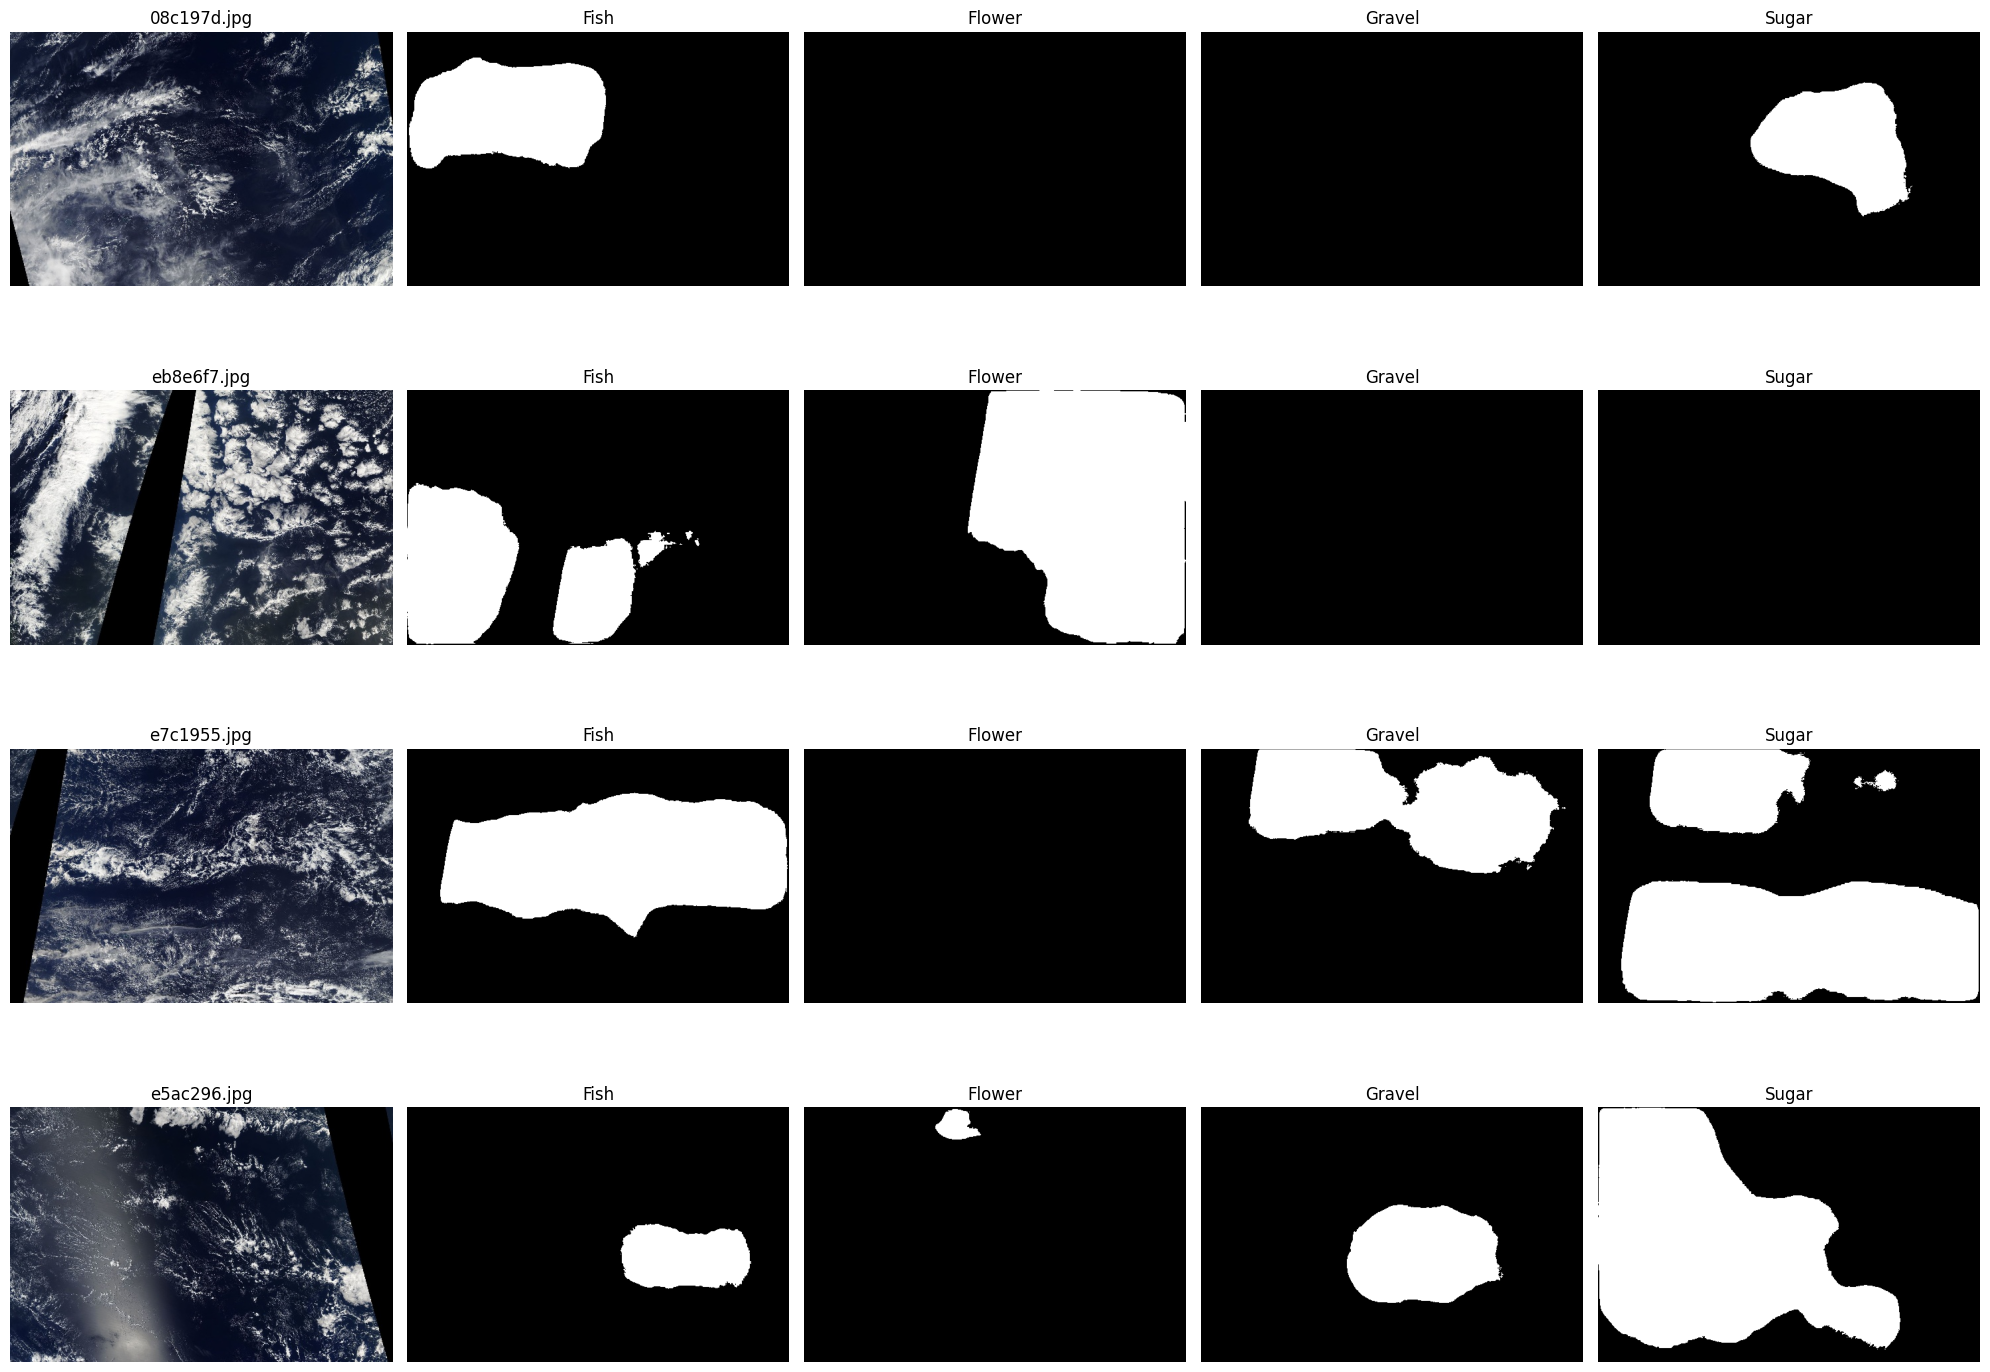

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

fig, ax = plt.subplots(
    4,
    5,
    figsize=(20, 15)
)

for row in range(4):

    # Original satellite image
    image = X_test[row].cpu().numpy().transpose(1, 2, 0)

    # Undo ImageNet normalization
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])

    image = image * std + mean
    image = np.clip(image, 0, 1)

    ax[row, 0].imshow(image)
    ax[row, 0].set_title(random_images[row])
    ax[row, 0].axis("off")

    # Fish / Flower / Gravel / Sugar
    for class_index, class_name in enumerate(CLASSES):

        mask = pred_mask[
            row,
            class_index
        ].cpu().numpy()

        ax[row, class_index + 1].imshow(
            mask,
            cmap="gray"
        )

        ax[row, class_index + 1].set_title(
            class_name
        )

        ax[row, class_index + 1].axis("off")

plt.tight_layout()
plt.show()

# RLE Encoding and Test Image Preparation

In [ ]:
HEIGHT = 384
WIDTH = 576

CLASSES = [
    "Fish",
    "Flower",
    "Gravel",
    "Sugar"
]

TEST_DIR = TEST_IMAGES_DIR

THRESHOLDS = np.array([
    0.5,   # Fish
    0.5,   # Flower
    0.5,   # Gravel
    0.5    # Sugar
])

BATCH_SIZE = 4


def rle_encode(mask):

    # Flatten in the same direction used by the decoder
    pixels = mask.flatten(order="F")

    # Add zeros at beginning and end
    pixels = np.concatenate(
        [[0], pixels, [0]]
    )

    # Find changes between 0 and 1
    runs = np.where(
        pixels[1:] != pixels[:-1]
    )[0] + 1

    # Convert start/end positions to start/length
    runs[1::2] -= runs[::2]

    return " ".join(
        str(x) for x in runs
    )


test_images = sorted([
    file
    for file in os.listdir(TEST_DIR)
    if file.lower().endswith(
        (".jpg", ".jpeg", ".png")
    )
])

print("Number of test images:", len(test_images))
print(test_images[:5])

Number of test images: 3698
['002f507.jpg', '0035ae9.jpg', '0038327.jpg', '004f759.jpg', '005ba08.jpg']


# Prediction on ALL Test Images

In [ ]:
all_predictions = []

model.eval()

for start in range(0, len(test_images), BATCH_SIZE):

    batch_images = test_images[start:start + BATCH_SIZE]

    X_batch = []

    for image_name in batch_images:

        image_path = os.path.join(TEST_DIR, image_name)

        image = cv2.imread(image_path)

        if image is None:
            raise FileNotFoundError(
                f"Could not load: {image_path}"
            )

        image = cv2.cvtColor(
            image,
            cv2.COLOR_BGR2RGB
        )

        image = cv2.resize(
            image,
            (WIDTH, HEIGHT)
        )

        image = image.astype(np.float32) / 255.0

        mean = np.array(
            [0.485, 0.456, 0.406]
        )

        std = np.array(
            [0.229, 0.224, 0.225]
        )

        image = (image - mean) / std

        image = image.transpose(2, 0, 1)

        X_batch.append(image)

    X_batch = torch.tensor(
        np.array(X_batch),
        dtype=torch.float32
    ).to(device)

    with torch.no_grad():

        logits = model(X_batch)

        probabilities = torch.sigmoid(logits)

        thresholds = torch.tensor(
            THRESHOLDS,
            dtype=torch.float32,
            device=device
        ).view(1, 4, 1, 1)

        predictions = (
            probabilities > thresholds
        ).float()

    all_predictions.append(
        predictions.cpu().numpy()
    )

all_predictions = np.concatenate(
    all_predictions,
    axis=0
)

print("Shape:", all_predictions.shape)
print("Dtype:", all_predictions.dtype)
print("Min:", all_predictions.min())
print("Max:", all_predictions.max())

Shape: (3698, 4, 384, 576)
Dtype: float32
Min: 0.0
Max: 1.0


# Create Final Output

In [ ]:
submission_rows = []

for image_index, image_name in enumerate(test_images):

    for class_index, class_name in enumerate(CLASSES):

        mask = all_predictions[
            image_index,
            class_index
        ]

        encoded_pixels = rle_encode(mask)

        submission_rows.append({
            "Image_Label": f"{image_name}_{class_name}",
            "EncodedPixels": encoded_pixels
        })

submission_df = pd.DataFrame(
    submission_rows
)

print("Output shape:", submission_df.shape)

print("\nFirst rows:")
print(submission_df.head())

Output shape: (14792, 2)

First rows:
          Image_Label                                      EncodedPixels
0    002f507.jpg_Fish                                                   
1  002f507.jpg_Flower                                                   
2  002f507.jpg_Gravel  403 84 489 43 534 15 557 5 586 2 595 25 711 2 ...
3   002f507.jpg_Sugar  144016 1 144396 1 144779 8 144788 1 145163 10 ...
4    0035ae9.jpg_Fish  146826 4 147209 6 147592 9 147976 6 148356 1 1...


# Save Final CSV

In [ ]:
OUTPUT_PATH = "/content/cloud_data/final_Testpredictions_ResNet50.csv"

submission_df.to_csv(
    OUTPUT_PATH,
    index=False
)

print("Final output saved to:")
print(OUTPUT_PATH)

Final output saved to:
/content/cloud_data/final_Testpredictions_ResNet50.csv


# Validate Final Submission

In [ ]:
OUTPUT_PATH = "/content/cloud_data/final_Testpredictions_ResNet50.csv"

final_df = pd.read_csv(OUTPUT_PATH)

print("Output shape:", final_df.shape)

print("\nColumns:")
print(final_df.columns.tolist())

print("\nFirst 8 rows:")
print(final_df.head(8))

print(
    "Number of unique images:",
    final_df["Image_Label"]
    .str.rsplit("_", n=1)
    .str[0]
    .nunique()
)

print("\nRows per image:")
print(
    final_df["Image_Label"]
    .str.rsplit("_", n=1)
    .str[0]
    .value_counts()
    .value_counts()
)

print("\nRows per class:")
print(
    final_df["Image_Label"]
    .str.rsplit("_", n=1)
    .str[1]
    .value_counts()
)

Output shape: (14792, 2)

Columns:
['Image_Label', 'EncodedPixels']

First 8 rows:
          Image_Label                                      EncodedPixels
0    002f507.jpg_Fish                                                NaN
1  002f507.jpg_Flower                                                NaN
2  002f507.jpg_Gravel  403 84 489 43 534 15 557 5 586 2 595 25 711 2 ...
3   002f507.jpg_Sugar  144016 1 144396 1 144779 8 144788 1 145163 10 ...
4    0035ae9.jpg_Fish  146826 4 147209 6 147592 9 147976 6 148356 1 1...
5  0035ae9.jpg_Flower                                                NaN
6  0035ae9.jpg_Gravel  490 2 494 1 500 3 561 1 572 7 580 4 591 2 598 ...
7   0035ae9.jpg_Sugar  22198 1 22581 5 22588 2 22591 1 22960 16 22978...
Number of unique images: 3698

Rows per image:
count
4    3698
Name: count, dtype: int64

Rows per class:
Image_Label
Fish      3698
Flower    3698
Gravel    3698
Sugar     3698
Name: count, dtype: int64


# Test Prediction Overlay Visualization

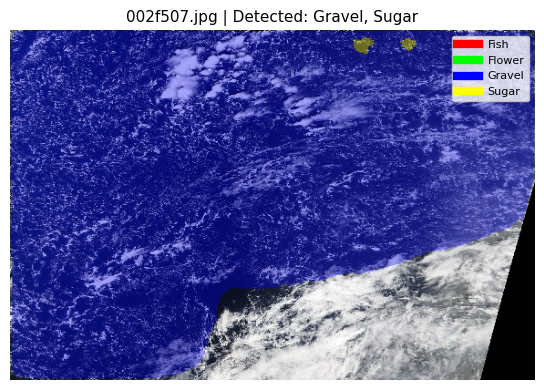

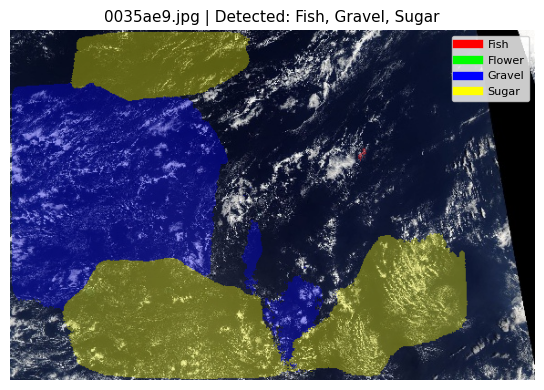

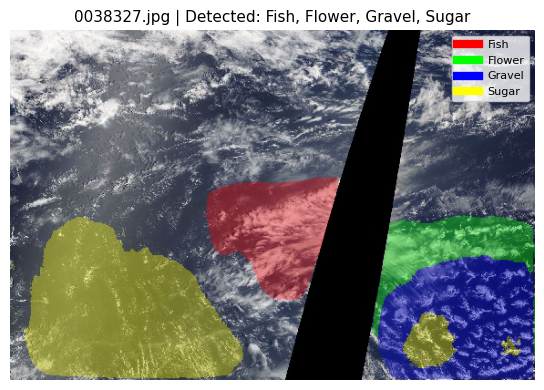

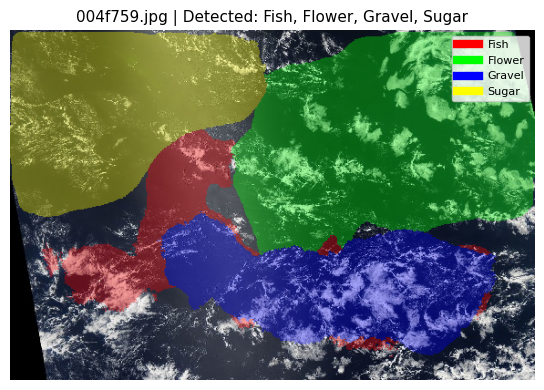

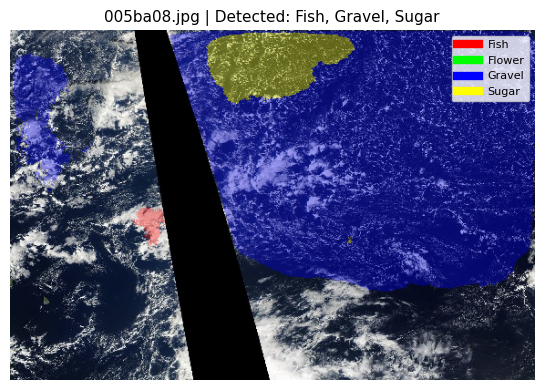

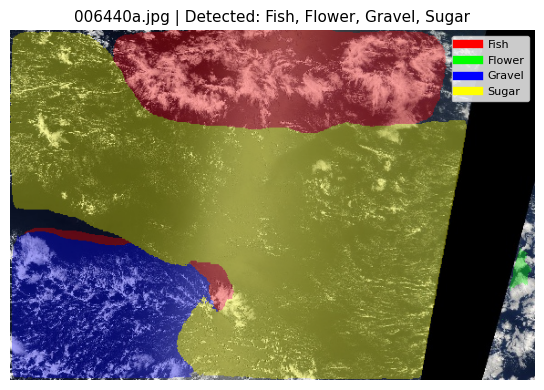

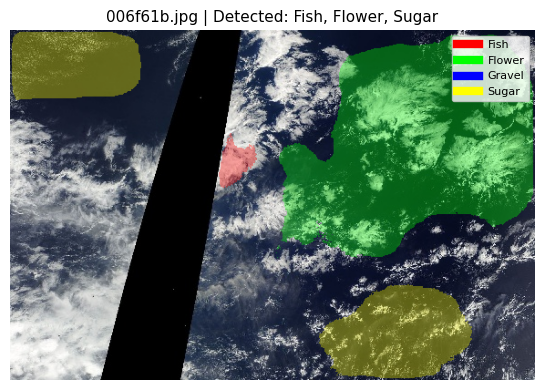

In [ ]:
N_IMAGES = 7

CLASSES = [
    "Fish",
    "Flower",
    "Gravel",
    "Sugar"
]

COLORS = [
    (255, 0, 0),      # Fish
    (0, 255, 0),      # Flower
    (0, 0, 255),      # Gravel
    (255, 255, 0)     # Sugar
]

for image_index in range(N_IMAGES):

    image_name = test_images[image_index]

    image_path = os.path.join(
        TEST_DIR,
        image_name
    )

    image = cv2.imread(image_path)

    image = cv2.cvtColor(
        image,
        cv2.COLOR_BGR2RGB
    )

    overlay = image.copy()

    detected_labels = []

    for class_index, class_name in enumerate(CLASSES):

        mask = all_predictions[
            image_index,
            class_index
        ]

        if mask.sum() > 0:

            detected_labels.append(class_name)

            overlay[mask == 1] = COLORS[class_index]

    result = cv2.addWeighted(
        image,
        0.65,
        overlay,
        0.35,
        0
    )

    plt.figure(figsize=(7, 4))

    plt.imshow(result)

    detected_text = (
        ", ".join(detected_labels)
        if detected_labels
        else "None"
    )

    plt.title(
        f"{image_name} | Detected: {detected_text}",
        fontsize=11
    )

    plt.axis("off")

    for class_name, color in zip(CLASSES, COLORS):

        plt.plot(
            [],
            [],
            color=np.array(color) / 255,
            linewidth=6,
            label=class_name
        )

    plt.legend(
        loc="upper right",
        fontsize=8
    )

    plt.tight_layout()
    plt.show()

| Model | Encoder | Best Epoch | Best Validation Dice | Final Train Loss | Final Validation Loss |
|---|---|---:|---:|---:|---:|
| **U-Net + ResNet34** | ResNet34 | 19 | **0.5974** | 0.5961 | 0.5825 |
| ✅ **U-Net + ResNet50** | ResNet50 | 25 | **0.6118** | 0.5584 | 0.5819 |
| **PSPNet + ResNet34** | ResNet34 | 15 | **0.6114** | 0.7730 | 0.7767 |

Final Model Comparison

Three segmentation models were compared using the overall (macro) Dice score. U-Net with ResNet50 achieved the highest score of 0.6118, followed very closely by PSPNet with ResNet34 with 0.6114. U-Net with ResNet34 achieved a score of 0.5974.

Based on the validation Dice score, U-Net with ResNet50 was selected as the best-performing model. However, the difference between U-Net with ResNet50 and PSPNet with ResNet34 is very small, so their performance can be considered very similar.

| Image | U-Net + ResNet50✅ | U-Net + ResNet34 | PSPNet + ResNet34 |
|---|---|---|---|
| `002f507.jpg` | Gravel, Sugar | Gravel, Sugar | Gravel, Sugar |
| `0035ae9.jpg` | Fish, Gravel, Sugar | Fish, Gravel, Sugar | Gravel, Sugar |
| `0038327.jpg` | Fish, Flower, Gravel, Sugar | Flower, Gravel, Sugar | Fish, Flower, Sugar |
| `004f759.jpg` | Fish, Flower, Gravel, Sugar | Fish, Flower, Sugar | Fish, Flower, Sugar |
| `005ba08.jpg` | Fish, Gravel, Sugar | Fish, Gravel | Gravel |
| `006440a.jpg` | Fish, Flower, Gravel, Sugar | Fish, Flower, Gravel, Sugar | — |
| `006f61b.jpg` | Fish, Flower, Sugar | Fish, Flower, Gravel, Sugar | — |

Comparison of Model Predictions

The three models were compared on the same test images. U-Net with ResNet50 generally detected more cloud classes than U-Net with ResNet34 and PSPNet with ResNet34. The results show some differences between the models, especially for Fish, Gravel, and Sugar.

This comparison is based only on the detected classes. Therefore, it does not show which model is more accurate without comparing the predictions with the ground truth.